# Three-signal sweep: is bipartite signalling merely a shortage of signals?

**The question.** In the poster's model there are three agent types but only two signals besides the null signal.
Perhaps one agent type splits only because there are not enough signals to go round. If so, the split should disappear
once every agent type could broadcast a signal of its own.

**What this notebook does.** It repeats the poster's final sweep (`final_sweep.ipynb`) with **three non-null
signals** (1, 2 and 3) instead of two. Everything else is the same:
* α .20–.36 × β .04–.20 in steps of .02 (81 points);
* N = 10,000 agents, 80,000 timesteps, random start;
* each non-null signal costs c = .001 per interaction; the null signal 0 is free, and an agent who broadcasts it does
  not attend to signals;
* replicator dynamics within each agent type, smart mutation m0 = .01, m1 = .1.

The one other difference: **100 runs per point** instead of 1,000, to get the answer quickly. These results are not on
the poster's heatmap; they back one bullet under it.

With three non-null signals a strategy profile is the signal broadcast plus an action for each of the four signals
received: 4 × 3⁴ = 324 profiles (81 with two signals).

**Names** (the code uses type numbers 0/1/2 and actions B/S/E):

| code | poster | share of population | payoff for coordinating |
|---|---|---|---|
| type 0 | **Bachites** | .33 + β | Bach 1 + α, Stravinsky 1, R&B .5 |
| type 1 | **Stravinskians** | .33 − β | Stravinsky 1 + α, Bach 1, R&B .5 |
| type 2 | **Millennials** | .34 | R&B 1, Bach 0, Stravinsky 0 |

**Which code runs.** The original model, `FNs_genBachStravinsky_v0055k_assort_FLIP7_rep_execNULLsig_SMARTmutation.py`,
unmodified, through the recording copy `FNs_genBS_PSA_bipartite.py` (lines 1–1554 identical to the original). The
original code is generic in the number of signals; `T.make_params(..., num_signals=4)` sets `numsignals_perdim = [4]`
(signal 0 plus three more). No model code changes.

**Seeding.** Each grid point has one fixed entropy, listed below. Run r of a point uses child r of
`SeedSequence(entropy).spawn(100)`. Every run can be re-simulated exactly; Part 1 ends with a check.

**Strict bipartite** is defined as on the poster:
1. one agent type ends split between two ways of signaling and conditioning actions on signals that earn it different
   payoffs, and the smaller half holds ≥ 10%;
2. the split held for the last 10,000 timesteps (25 snapshots, 400 timesteps apart);
3. the final state is an ε-Nash equilibrium with ε = .001: no agent can gain more than .001 per interaction by changing
   its strategy profile.

**Data.** The runs are saved to `results/three_signal_sweep/` (one `.npz` per point). These files are **not
distributed**: run this notebook to re-create them (about 3 hours with 20 worker processes). Re-running skips points
whose file exists, so with the data present it only redraws the results.


In [1]:
import json, os, time
import numpy as np
import psa_bipartite_tools as T      # make_params, screen_point, run_batch, detectors (see that file)
import exploration_log as X          # CURRENT_/PAST_ progress report (project convention)

ALPHAS = [0.2, 0.22, 0.24, 0.26, 0.28, 0.3, 0.32, 0.34, 0.36]      # extra payoff for coordinating on one's favourite action
BETAS  = [0.04, 0.06, 0.08, 0.1, 0.12, 0.14, 0.16, 0.18, 0.2]      # Bachites' share = .33 + beta, Stravinskians' share = .33 - beta
NUM_SIGNALS = 4            # signal 0 (null) + three non-null signals; the poster's model has 3 (0 + two)
RUNS = 100                 # runs per grid point (the poster's sweep: 1,000)
N = 10_000                 # population size
SIGNAL_COST = 0.001        # cost per interaction of broadcasting any non-null signal (signal 0 is free)
M0, M1 = 0.01, 0.1         # smart-mutation rates
THRDS = 20                 # worker processes
OUT = 'results/three_signal_sweep'
os.makedirs(OUT, exist_ok=True)

def point_path(a, b):
    return f'{OUT}/N{N}_a{a:.2f}_b{b:.2f}_runs{RUNS}_c{SIGNAL_COST:g}_sig{NUM_SIGNALS}.npz'


## The entropy of every grid point

Drawn once with `numpy.random.SeedSequence().entropy` on 2026-11-18 and fixed here (each point's `.npz` also stores it as
`entropy`). Run r of point (α, β) is seeded with `SeedSequence(ENTROPY[(α, β)]).spawn(100)[r]`.

In [2]:
ENTROPY = {
    (0.20, 0.04): 191056617626326626339003135897925990065,
    (0.20, 0.06): 96478350547198213139833595328682858380,
    (0.20, 0.08): 243540601542822167647666650332716494431,
    (0.20, 0.10): 191800615656875875410035547193471797581,
    (0.20, 0.12): 171005736504092424015590575577288007743,
    (0.20, 0.14): 43369551899874854917480872021809697513,
    (0.20, 0.16): 38740686557096937943263990332823072563,
    (0.20, 0.18): 268269088934647296512472000579002011537,
    (0.20, 0.20): 64456334996234372350793317303190999007,
    (0.22, 0.04): 50979681821521291302910142817606422633,
    (0.22, 0.06): 165577790480564889830185723590089400228,
    (0.22, 0.08): 159443791741258115599647797898593256479,
    (0.22, 0.10): 200579823065110797924461338221143310568,
    (0.22, 0.12): 336467630896938210362706787411521750624,
    (0.22, 0.14): 304513841097208296216626790022758788332,
    (0.22, 0.16): 264251621347659021919473385398382124570,
    (0.22, 0.18): 31830522624229435184680531082078957781,
    (0.22, 0.20): 43483260090114592450658585651841168076,
    (0.24, 0.04): 166564076599497365148855415372903309903,
    (0.24, 0.06): 185277495814551089327444125331591108110,
    (0.24, 0.08): 99884962749148027776687807390119767519,
    (0.24, 0.10): 159785684115492809296501294807687431940,
    (0.24, 0.12): 268549681305836974613954229604212680533,
    (0.24, 0.14): 94230462632861113275357043458458609623,
    (0.24, 0.16): 115473823546079628744054926729435368842,
    (0.24, 0.18): 68364139529516649707285238416770785029,
    (0.24, 0.20): 15400322578245654077723246370006611,
    (0.26, 0.04): 208779155624018536762683359903355286443,
    (0.26, 0.06): 107209412310703023928760794471505574346,
    (0.26, 0.08): 47984455585239643243756447355747048775,
    (0.26, 0.10): 304188880591336532341409617476287560968,
    (0.26, 0.12): 261433211699832755523060034022370235463,
    (0.26, 0.14): 334546818770628410439873479461281463201,
    (0.26, 0.16): 89973666076514653426348325898214069957,
    (0.26, 0.18): 250374858244713940301464870731741872592,
    (0.26, 0.20): 87077863675857322431476982200241063660,
    (0.28, 0.04): 223644740692039497800157267628971608478,
    (0.28, 0.06): 278399749928319031203898452649005388676,
    (0.28, 0.08): 258855117883934200460914961928820004350,
    (0.28, 0.10): 12236970792969017933512275126212221551,
    (0.28, 0.12): 279259721279987225748001516491795222846,
    (0.28, 0.14): 241375035450141751518186417753409789922,
    (0.28, 0.16): 22987999623954965285070449683875665212,
    (0.28, 0.18): 96832321605654157196403460561282916979,
    (0.28, 0.20): 291297321933940866994122051115418360302,
    (0.30, 0.04): 249523106207125772785246319630307299749,
    (0.30, 0.06): 7551418702591589627865416563890140623,
    (0.30, 0.08): 17028151478943536629997235366421338339,
    (0.30, 0.10): 164004280475002578632942772312426366706,
    (0.30, 0.12): 167905724739353016185470358793831426417,
    (0.30, 0.14): 75805601050374810535933339777637197633,
    (0.30, 0.16): 286437327314290820633832322748375098467,
    (0.30, 0.18): 41109442255833931825736277726175939241,
    (0.30, 0.20): 189676354861931772273646805507389629459,
    (0.32, 0.04): 334253732329150628265357450444222085653,
    (0.32, 0.06): 239714891241007972268888821121332340805,
    (0.32, 0.08): 230730370577167873380583736526066782988,
    (0.32, 0.10): 197548946418862000214694356477771393152,
    (0.32, 0.12): 204372914202867953719328389785974912126,
    (0.32, 0.14): 119247187904066310119227530483337648775,
    (0.32, 0.16): 193134895995459721080877719441208427791,
    (0.32, 0.18): 124194529722656792043883614606640751386,
    (0.32, 0.20): 263456139064036632096394825073207964920,
    (0.34, 0.04): 139418922173572806841547751400917641029,
    (0.34, 0.06): 217480252786403380680538694094936582863,
    (0.34, 0.08): 103709334988109135533099573904786442233,
    (0.34, 0.10): 227743109617876605573050102975793923309,
    (0.34, 0.12): 268380443756556431617995961751790406304,
    (0.34, 0.14): 165582547121605569985221238637252565495,
    (0.34, 0.16): 6205259395252119766779610261109810264,
    (0.34, 0.18): 32905975203285895874128280791256115890,
    (0.34, 0.20): 55412794246878186687906660114222625015,
    (0.36, 0.04): 224658621256605880548015951372548217809,
    (0.36, 0.06): 301295100235910789613010912924975425163,
    (0.36, 0.08): 14523870364478236498106885648187738191,
    (0.36, 0.10): 64504098366606829035845289110928277887,
    (0.36, 0.12): 292956179748651184666258952984193083822,
    (0.36, 0.14): 160276877802837857264387725961132155841,
    (0.36, 0.16): 127212730167095709010363200337380174985,
    (0.36, 0.18): 159174425577199930052723284788415469887,
    (0.36, 0.20): 166795013316996507022166842636552049086,
}

assert len(ENTROPY) == len(ALPHAS) * len(BETAS) == len(set(ENTROPY.values()))
print('81 fixed entropies, one per grid point; e.g. (0.30, 0.12) ->', ENTROPY[(0.30, 0.12)])

81 fixed entropies, one per grid point; e.g. (0.30, 0.12) -> 167905724739353016185470358793831426417


## Part 1 — the sweep

For each grid point, `T.screen_point` builds the parameters (`T.make_params` with `num_signals=4`), runs the 100 seeded
simulations in parallel, tests every run for a split, its stability and ε-Nash, and saves everything to the point's
`.npz`. Points whose file exists are skipped. A progress report `CURRENT_exploration_<desc>.md` in the project folder is
rewritten after every point and archived to `archives/PAST_NN_...` at the end.

In [3]:
timing_path = f'{OUT}/timing.json'
timing = json.load(open(timing_path)) if os.path.exists(timing_path) else {}
key = lambda a, b: f'N={N} α={a:.2f} β={b:.2f} runs={RUNS} c={SIGNAL_COST:g} signals={NUM_SIGNALS}'
todo = [(a, b) for a in ALPHAS for b in BETAS if not os.path.exists(point_path(a, b))]
print(f'{81 - len(todo)} of 81 points already saved; {len(todo)} to simulate')
if todo:
    E = X.Exploration(
        'a0.20-0.36_b0.04-0.20_c0.001_N10000_sig4_three_signal_sweep',
        'Three-signal sweep: the poster grid with 3 non-null signals (9 x 9 grid, 100 runs per point)',
        'User request 2026-11-18: "Is this merely a consequence of not having enough signals?" Same grid and settings as the '
        'final poster sweep, but signals 0 (null) + 1, 2, 3 (324 strategy profiles); 100 runs per point for speed.',
        [f'grid: alpha {ALPHAS[0]:.2f}-{ALPHAS[-1]:.2f} x beta {BETAS[0]:.2f}-{BETAS[-1]:.2f}, step .02; {RUNS} runs/point; N {N:,}; '
         f'signal cost {SIGNAL_COST} per non-null signal; mutation m0 {M0}, m1 {M1}; T = 80,000 steps; null signal; {NUM_SIGNALS} signals',
         'run from three_signal_sweep.ipynb (fixed entropies listed in the notebook)',
         f'results: {OUT}/ (one .npz per point)', f'threads: {THRDS}'],
        [(key(a, b), N * RUNS) for a in ALPHAS for b in BETAS],
        footer=['Re-run three_signal_sweep.ipynb to resume (finished points are skipped).'])
    for a in ALPHAS:
        for b in BETAS:
            p = point_path(a, b)
            if os.path.exists(p):
                E.add(key(a, b), X.point_report(p), note='   (finished earlier)')
                continue
            t0 = time.perf_counter()
            s = T.screen_point(a, b, RUNS, p, population_size=N, thrds=THRDS, mutation_rate=(M0, M1),
                               signal_cost=-SIGNAL_COST, num_signals=NUM_SIGNALS, entropy=ENTROPY[(a, b)])
            m = (time.perf_counter() - t0) / 60
            timing[f'{a:.2f},{b:.2f}'] = m
            json.dump(timing, open(timing_path, 'w'), indent=1)
            E.add(key(a, b), X.point_report(p), minutes=m)
            print(f'alpha {a:.2f} beta {b:.2f}: strict bipartite {s["bipartite"]:3d} / {RUNS}   [{m:.1f} min]', flush=True)
    print('report archived to', E.finish())

# summary table read from the saved files
STRICT = np.full((len(ALPHAS), len(BETAS)), -1)
for i, a in enumerate(ALPHAS):
    for j, b in enumerate(BETAS):
        if os.path.exists(point_path(a, b)):
            d = np.load(point_path(a, b), allow_pickle=True)
            assert int(d['entropy'].item()) == ENTROPY[(a, b)] and int(d['runs']) == RUNS
            assert int(d['num_signals']) == NUM_SIGNALS
            STRICT[i, j] = int(d['bipartite'].sum())
print(f'\nstrict bipartite runs per {RUNS} (rows alpha, columns beta; -1 = not run yet)')
print('alpha\\beta ' + ' '.join(f'{b:5.2f}' for b in BETAS))
for i, a in enumerate(ALPHAS):
    print(f'{a:9.2f}  ' + ' '.join(f'{v:5d}' for v in STRICT[i]))
if timing:
    print(f'\nsimulation time: {sum(timing.values()) / 60:.1f} h for {len(timing)} points ({np.mean(list(timing.values())):.1f} min/point)')

81 of 81 points already saved; 0 to simulate

strict bipartite runs per 100 (rows alpha, columns beta; -1 = not run yet)
alpha\beta  0.04  0.06  0.08  0.10  0.12  0.14  0.16  0.18  0.20
     0.20      5     3     3     6     3     6     3     3     7
     0.22      1     3     1     7     9     3     3     4     7
     0.24      2     6     9    19    40    25    22    25    16
     0.26     36    54    62    67    54    40    32    31    21
     0.28     13    50    60    67    70    68    52    38    29
     0.30      5    25    64    67    67    67    49    30    36
     0.32      3     4    46    55    71    63    56    40    29
     0.34      3     4     8    62    74    66    52    41    35
     0.36      0     2     0    30    60    72    51    40    26

simulation time: 2.9 h for 81 points (2.1 min/point)


### Check: a saved run can be re-simulated exactly from its entropy

Re-runs runs 0 and 1 of the point α .30, β .12 and compares their final counts with the saved ones.

In [4]:
a, b = 0.30, 0.12
d = np.load(point_path(a, b), allow_pickle=True)
P = T.file_params(d)
assert P['numsignals'] == NUM_SIGNALS
B = T.run_batch(P, RUNS, entropy=ENTROPY[(a, b)], thrds=2, run_ids=[0, 1], keep_profile_time=False)
for i, r in enumerate([0, 1]):
    same = np.array_equal(B['final_counts'][i], d['final_counts'][r])
    print(f'run {r}: re-simulated final counts identical to the saved ones: {same}')
    assert same

run 0: re-simulated final counts identical to the saved ones: True
run 1: re-simulated final counts identical to the saved ones: True


## Part 2 — compared with two non-null signals

The two-signal counts are the poster's final sweep (`final_sweep.ipynb`, 1,000 runs per point), copied here as
literals; if that sweep's files are present they are checked against them. Both are shown as **% of runs**, on the same
colour scale. With 100 runs a cell's percentage is uncertain by about ±5 points (binomial standard error at 30%).

In [5]:
TWO_SIGNAL_STRICT = {
    (0.20, 0.04): 24,
    (0.20, 0.06): 25,
    (0.20, 0.08): 20,
    (0.20, 0.10): 10,
    (0.20, 0.12): 1,
    (0.20, 0.14): 0,
    (0.20, 0.16): 0,
    (0.20, 0.18): 4,
    (0.20, 0.20): 171,
    (0.22, 0.04): 18,
    (0.22, 0.06): 30,
    (0.22, 0.08): 14,
    (0.22, 0.10): 7,
    (0.22, 0.12): 1,
    (0.22, 0.14): 10,
    (0.22, 0.16): 21,
    (0.22, 0.18): 19,
    (0.22, 0.20): 172,
    (0.24, 0.04): 14,
    (0.24, 0.06): 23,
    (0.24, 0.08): 23,
    (0.24, 0.10): 19,
    (0.24, 0.12): 76,
    (0.24, 0.14): 107,
    (0.24, 0.16): 91,
    (0.24, 0.18): 72,
    (0.24, 0.20): 181,
    (0.26, 0.04): 35,
    (0.26, 0.06): 100,
    (0.26, 0.08): 333,
    (0.26, 0.10): 503,
    (0.26, 0.12): 462,
    (0.26, 0.14): 351,
    (0.26, 0.16): 236,
    (0.26, 0.18): 180,
    (0.26, 0.20): 238,
    (0.28, 0.04): 13,
    (0.28, 0.06): 50,
    (0.28, 0.08): 222,
    (0.28, 0.10): 509,
    (0.28, 0.12): 534,
    (0.28, 0.14): 411,
    (0.28, 0.16): 369,
    (0.28, 0.18): 248,
    (0.28, 0.20): 210,
    (0.30, 0.04): 10,
    (0.30, 0.06): 12,
    (0.30, 0.08): 75,
    (0.30, 0.10): 311,
    (0.30, 0.12): 549,
    (0.30, 0.14): 443,
    (0.30, 0.16): 378,
    (0.30, 0.18): 282,
    (0.30, 0.20): 222,
    (0.32, 0.04): 6,
    (0.32, 0.06): 14,
    (0.32, 0.08): 18,
    (0.32, 0.10): 110,
    (0.32, 0.12): 388,
    (0.32, 0.14): 445,
    (0.32, 0.16): 422,
    (0.32, 0.18): 282,
    (0.32, 0.20): 223,
    (0.34, 0.04): 4,
    (0.34, 0.06): 6,
    (0.34, 0.08): 9,
    (0.34, 0.10): 28,
    (0.34, 0.12): 176,
    (0.34, 0.14): 422,
    (0.34, 0.16): 425,
    (0.34, 0.18): 285,
    (0.34, 0.20): 227,
    (0.36, 0.04): 7,
    (0.36, 0.06): 5,
    (0.36, 0.08): 6,
    (0.36, 0.10): 8,
    (0.36, 0.12): 34,
    (0.36, 0.14): 239,
    (0.36, 0.16): 419,
    (0.36, 0.18): 347,
    (0.36, 0.20): 237,
}   # strict bipartite runs per 1,000, final_sweep.ipynb
TWO_RUNS = 1000
for (a, b), v in TWO_SIGNAL_STRICT.items():      # check against the final sweep's files when they are present
    f = f'results/final_sweep/N{N}_a{a:.2f}_b{b:.2f}_runs{TWO_RUNS}_c{SIGNAL_COST:g}.npz'
    if os.path.exists(f):
        assert int(np.load(f, allow_pickle=True)['bipartite'].sum()) == v, f
TWO = np.array([[TWO_SIGNAL_STRICT[(a, b)] for b in BETAS] for a in ALPHAS])
assert (STRICT >= 0).all(), 'Part 1 has not finished all 81 points'

pct2, pct3 = 100 * TWO / TWO_RUNS, 100 * STRICT / RUNS
tot2, tot3 = TWO.sum(), STRICT.sum()
print(f'two non-null signals:   {tot2:,} of {81 * TWO_RUNS:,} runs bipartite ({100 * tot2 / (81 * TWO_RUNS):.1f}%)')
print(f'three non-null signals: {tot3:,} of {81 * RUNS:,} runs bipartite ({100 * tot3 / (81 * RUNS):.1f}%)')
i2, i3 = np.unravel_index(np.argmax(pct2), pct2.shape), np.unravel_index(np.argmax(pct3), pct3.shape)
print(f'most bipartite: two signals {pct2[i2]:.1f}% at alpha {ALPHAS[i2[0]]:.2f} beta {BETAS[i2[1]]:.2f}; '
      f'three signals {pct3[i3]:.0f}% at alpha {ALPHAS[i3[0]]:.2f} beta {BETAS[i3[1]]:.2f}')
diff = pct3 - pct2
print(f'cells where three signals give more / fewer bipartite runs by > 10 points: {(diff > 10).sum()} / {(diff < -10).sum()} of 81')
print('\ndifference, three minus two signals (percentage points; rows alpha, columns beta)')
print('alpha\\beta ' + ' '.join(f'{b:6.2f}' for b in BETAS))
for i, a in enumerate(ALPHAS):
    print(f'{a:9.2f}  ' + ' '.join(f'{v:+6.0f}' for v in diff[i]))

two non-null signals:   13,231 of 81,000 runs bipartite (16.3%)
three non-null signals: 2,488 of 8,100 runs bipartite (30.7%)
most bipartite: two signals 54.9% at alpha 0.30 beta 0.12; three signals 74% at alpha 0.34 beta 0.12
cells where three signals give more / fewer bipartite runs by > 10 points: 39 / 2 of 81

difference, three minus two signals (percentage points; rows alpha, columns beta)
alpha\beta   0.04   0.06   0.08   0.10   0.12   0.14   0.16   0.18   0.20
     0.20      +3     +0     +1     +5     +3     +6     +3     +3    -10
     0.22      -1     +0     -0     +6     +9     +2     +1     +2    -10
     0.24      +1     +4     +7    +17    +32    +14    +13    +18     -2
     0.26     +32    +44    +29    +17     +8     +5     +8    +13     -3
     0.28     +12    +45    +38    +16    +17    +27    +15    +13     +8
     0.30      +4    +24    +56    +36    +12    +23    +11     +2    +14
     0.32      +2     +3    +44    +44    +32    +18    +14    +12     +7
     0.34 

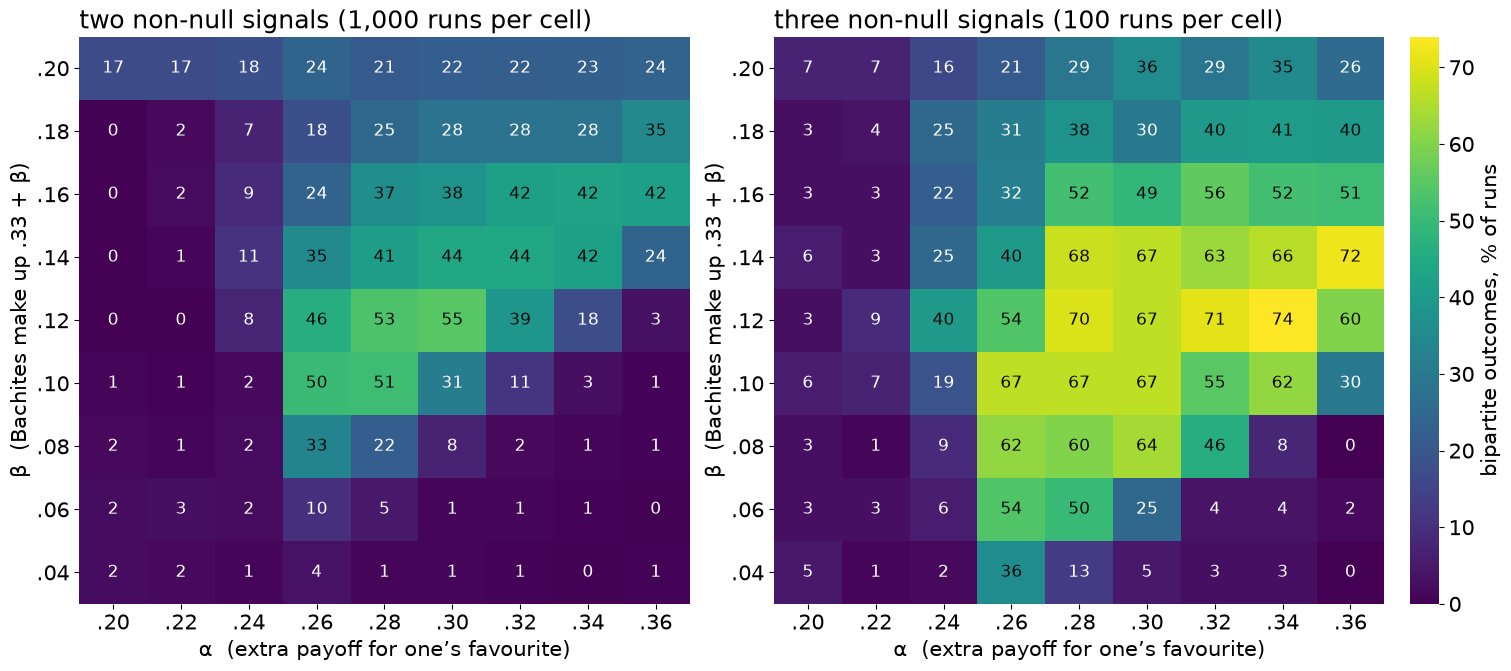

In [6]:
import matplotlib.pyplot as plt
FIG = f'{OUT}/figures'
os.makedirs(FIG, exist_ok=True)
INK = '#0b0b0b'

def luminance(rgb):
    c = [x / 12.92 if x <= .04045 else ((x + .055) / 1.055) ** 2.4 for x in rgb[:3]]
    return .2126 * c[0] + .7152 * c[1] + .0722 * c[2]

def text_on(bg):        # white or black, whichever contrasts more with the cell
    lb = luminance(bg)
    return 'white' if 1.05 / (lb + .05) > (lb + .05) / (luminance((.043, .043, .043)) + .05) else INK

plt.rcParams.update({'font.size': 15, 'font.family': 'DejaVu Sans'})
fig, axes = plt.subplots(1, 2, figsize=(15, 6.6), facecolor='white', constrained_layout=True)
vmax = max(pct2.max(), pct3.max())
cmap = plt.get_cmap('viridis')
for ax, Z, title in ((axes[0], pct2, f'two non-null signals ({TWO_RUNS:,} runs per cell)'),
                     (axes[1], pct3, f'three non-null signals ({RUNS} runs per cell)')):
    im = ax.imshow(Z.T, origin='lower', cmap=cmap, vmin=0, vmax=vmax, aspect='auto')
    for i in range(Z.shape[0]):
        for j in range(Z.shape[1]):
            ax.text(i, j, f'{Z[i, j]:.0f}', ha='center', va='center', fontsize=12, color=text_on(cmap(Z[i, j] / vmax)))
    ax.set_xticks(range(len(ALPHAS)), [f'{a:.2f}'[1:] for a in ALPHAS])
    ax.set_yticks(range(len(BETAS)), [f'{b:.2f}'[1:] for b in BETAS])
    ax.set_xlabel('α  (extra payoff for one’s favourite)')
    ax.set_ylabel('β  (Bachites make up .33 + β)')
    ax.set_title(title, loc='left')
    for s in ax.spines.values():
        s.set_visible(False)
cb = fig.colorbar(im, ax=axes, fraction=.04, pad=.02)
cb.set_label('bipartite outcomes, % of runs')
cb.outline.set_visible(False)
for ext in ('pdf', 'png'):
    fig.savefig(f'{FIG}/two_vs_three_signals.{ext}', dpi=150)
plt.show()

## Part 3 — which kinds of bipartite outcome, and is the extra signal used?

**Kinds up to isomorphism**, as on the poster (`isomorphism_check.py`): an outcome is described by who broadcasts which
signal (the split type's two halves count as two groups) and what every pair of groups, and each group with itself,
coordinates on. Two outcomes are the same kind if they match after relabelling the non-null signals (any permutation
of 1, 2, 3), or after swapping Bachites with Stravinskians together with Bach with Stravinsky. Each kind is matched to
its rank among the two-signal kinds (poster: 1 = most common, 3 = third most common), by identical canonical form.

**Is the extra signal used?** For each run: how many non-null signals are broadcast by at least 1% of the population,
and whether the three agent types each hold a signal of their own (each type's most common signal is non-null,
different from the other two types', and broadcast by ≥ 90% of the type).

In [7]:
import pandas as pd
import isomorphism_check as I

TWO_SIGNAL_KINDS = [   # canonical forms of the two-signal kinds (final sweep; results/final_sweep/isomorphism_classes.csv), most common first
    ("(((0, 0), (0, 1), (1, 1), (2, 2)), ('B', 'B', 'B', '-', 'S', 'S', 'E', 'S', 'E', 'E'))", 12228),
    ("(((0, 0), (0, 1), (1, 1), (2, 1)), ('B', 'B', 'B', '-', 'E', 'E', 'E', 'E', 'E', 'E'))", 533),
    ("(((0, 0), (1, 1), (1, 2), (2, 0)), ('B', 'B', 'B', '-', 'B', 'S', '-', 'B', '-', 'E'))", 425),
    ("(((0, 1), (0, 2), (1, 1), (2, 0)), ('S', 'B', 'S', 'E', 'S', 'B', 'E', 'S', 'E', 'E'))", 25),
    ("(((0, 0), (1, 1), (1, 2), (2, 1)), ('B', 'B', 'B', '-', 'E', 'S', 'E', 'B', '-', 'E'))", 10),
    ("(((0, 0), (1, 1), (1, 2), (2, 1)), ('B', 'B', 'B', '-', 'E', 'S', 'E', 'S', '-', 'E'))", 7),
    ("(((0, 1), (0, 2), (1, 1), (2, 0)), ('S', 'B', 'S', 'E', 'E', 'B', 'E', 'S', 'E', 'E'))", 3),
]
two_rank = {c: i + 1 for i, (c, _) in enumerate(TWO_SIGNAL_KINDS)}

files = [point_path(a, b) for a in ALPHAS for b in BETAS]
runs_df = I.classify_runs(files)                      # sets T to 4 signals from the files
assert T.NUMSIGNALS == NUM_SIGNALS and len(runs_df) == tot3
kinds = I.class_table(runs_df)
kinds['two_signal_rank'] = [two_rank.get(c, '-') for c in kinds.canon]
runs_df.to_csv(f'{OUT}/isomorphism_runs.csv', index=False)
kinds.to_csv(f'{OUT}/isomorphism_classes.csv', index=False)
print(f'{len(runs_df):,} bipartite runs in {len(kinds)} kinds up to isomorphism\n')
pd.set_option('display.width', 220, 'display.max_colwidth', 90)
print(kinds[['class', 'runs', 'share', 'two_signal_rank', 'boxes', 'edges']].to_string(index=False,
      formatters={'share': '{:.1%}'.format}))

def signals_in_use(C):
    tot = C.sum(0)
    return [s for s in range(1, NUM_SIGNALS) if tot[T.PROFILES[:, 0] == s].sum() >= .01 * tot.sum()]

def own_signals(C):
    modal = []
    for t in range(3):
        per = np.array([C[t][T.PROFILES[:, 0] == s].sum() for s in range(NUM_SIGNALS)])
        if per.max() < .9 * C[t].sum():
            return False
        modal.append(int(per.argmax()))
    return 0 not in modal and len(set(modal)) == 3

rows = []
for f in files:
    d = np.load(f, allow_pickle=True)
    for r in range(RUNS):
        C = d['final_counts'][r]
        rows.append(dict(bipartite=bool(d['bipartite'][r]), n_used=len(signals_in_use(C)), own=own_signals(C)))
use = pd.DataFrame(rows)
bp = use[use.bipartite]
print(f'\nbipartite runs that leave a non-null signal unused: {(bp.n_used < NUM_SIGNALS - 1).mean():.1%} '
      f'({(bp.n_used < NUM_SIGNALS - 1).sum():,} of {len(bp):,})')
print(f'all runs that leave a non-null signal unused: {(use.n_used < NUM_SIGNALS - 1).mean():.1%}')
print(f'runs in which every agent type holds a non-null signal of its own: {use.own.mean():.1%} of all runs, '
      f'{bp.own.mean():.1%} of bipartite runs')
print('non-null signals in use, bipartite runs:', dict(bp.n_used.value_counts().sort_index()))

2,488 bipartite runs in 18 kinds up to isomorphism

 class  runs share two_signal_rank                                                                                      boxes                                                                      edges
     1  2239 90.0%               1                      Bachites/sig0 + Bachites/sig1 + Stravinskians/sig1 + Millennials/sig2                          00:B 01:B 02:B 03:- 11:S 12:S 13:E 22:S 23:E 33:E
     2    91  3.7%               -                      Bachites/sig1 + Bachites/sig2 + Stravinskians/sig1 + Millennials/sig3                          00:S 01:B 02:S 03:E 11:E 12:B 13:E 22:S 23:E 33:E
     3    85  3.4%               -                      Bachites/sig1 + Bachites/sig2 + Stravinskians/sig1 + Millennials/sig3                          00:S 01:B 02:S 03:E 11:S 12:B 13:E 22:S 23:E 33:E
     4    16  0.6%               -                      Bachites/sig1 + Bachites/sig2 + Stravinskians/sig3 + Millennials/sig0                   


bipartite runs that leave a non-null signal unused: 90.8% (2,258 of 2,488)
all runs that leave a non-null signal unused: 83.1%
runs in which every agent type holds a non-null signal of its own: 13.4% of all runs, 0.0% of bipartite runs
non-null signals in use, bipartite runs: {1: np.int64(14), 2: np.int64(2244), 3: np.int64(230)}


## Summary for the poster

The numbers quoted in the poster's bullet, also written to `results/three_signal_sweep/summary.json`.

In [8]:
first = kinds.iloc[0]
summary = dict(
    runs=int(81 * RUNS), bipartite=int(tot3), bipartite_pct=round(100 * tot3 / (81 * RUNS), 1),
    two_signal_runs=int(81 * TWO_RUNS), two_signal_bipartite=int(tot2), two_signal_pct=round(100 * tot2 / (81 * TWO_RUNS), 1),
    best_pct=int(pct3.max()), best_alpha=float(ALPHAS[i3[0]]), best_beta=float(BETAS[i3[1]]),
    kinds=int(len(kinds)), top_kind_share_pct=round(100 * float(first.share), 1), top_kind_two_signal_rank=first.two_signal_rank,
    bipartite_unused_signal_pct=round(100 * float((bp.n_used < NUM_SIGNALS - 1).mean()), 1),
    own_signal_pct_all=round(100 * float(use.own.mean()), 1), own_signal_pct_bipartite=round(100 * float(bp.own.mean()), 1),
    cells_more=int((diff > 10).sum()), cells_fewer=int((diff < -10).sum()))
summary = {k: (v if not isinstance(v, (np.integer,)) else int(v)) for k, v in summary.items()}
json.dump(summary, open(f'{OUT}/summary.json', 'w'), indent=1)
print(json.dumps(summary, indent=1))

{
 "runs": 8100,
 "bipartite": 2488,
 "bipartite_pct": 30.7,
 "two_signal_runs": 81000,
 "two_signal_bipartite": 13231,
 "two_signal_pct": 16.3,
 "best_pct": 74,
 "best_alpha": 0.34,
 "best_beta": 0.12,
 "kinds": 18,
 "top_kind_share_pct": 90.0,
 "top_kind_two_signal_rank": 1,
 "bipartite_unused_signal_pct": 90.8,
 "own_signal_pct_all": 13.4,
 "own_signal_pct_bipartite": 0.0,
 "cells_more": 39,
 "cells_fewer": 2
}
